# NSPPK Simplex Features: Larger Graphs and HIV

This notebook shows how NSPPK's active feature bins change as `radius`, `distance`, and `connector` vary. It starts with a larger labeled graph, where we inspect an exact pair of roots and a hashed triangle feature, then compares runtime and classification accuracy on a reproducible, class-balanced sample from the bundled HIV dataset.

The simplex comparison enables `use_simplex_features=True` with `simplex_feature_order=2`, which includes nodes, edges, and triangles. The HIV section uses one fixed train/test split so every configuration sees the same molecules. Increase `SAMPLE_PER_CLASS` or add repeated splits when you want a more stable accuracy estimate.

In [1]:
from pathlib import Path
import pickle
import sys
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nsppk import NSPPK

RANDOM_STATE = 2026
NBITS = 12
SIMPLEX_FEATURE_ORDER = 2
HIV_PICKLE = REPO_ROOT / 'data' / 'HIV_networkx_graphs.pkl'

## 1. Larger labeled graph: inspect a distance-4 pair and count active feature bins

The example is a dumbbell graph: two dense lobes centered on the selected roots, joined by a thick bridge with many shortest routes. The parameter sweeps compare:

- `radius = 0, 1, 2` with `distance=0`, `connector=0`
- `distance = 0, 1, 2, 3, 4` with `radius=1`, `connector=0`
- `connector = 0, 1, 2` with `radius=1`, `distance=4`

Each setting runs once with simplex features off and once with nodes, edges, and triangles enabled. `active_feature_bins` counts nonzero hashed columns (including the two reserved columns); hash collisions mean this is a bin count, not a count of raw fragment occurrences.

nodes=12, edges=30, density=0.45


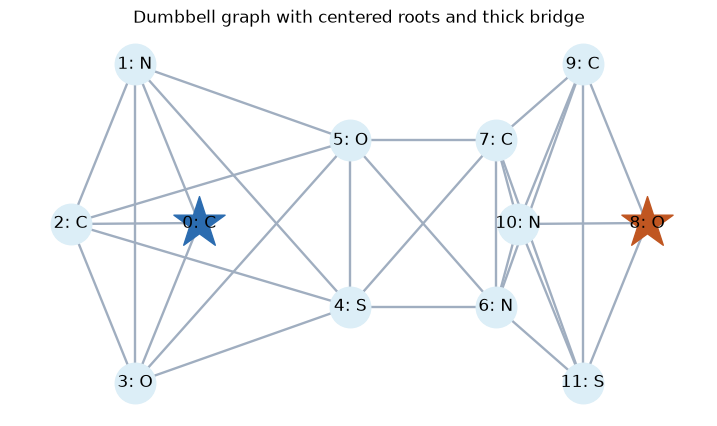

In [2]:
dense_graph = nx.Graph()
node_labels = {
    0: 'C', 1: 'N', 2: 'C', 3: 'O',
    4: 'S', 5: 'O', 6: 'N', 7: 'C',
    8: 'O', 9: 'C', 10: 'N', 11: 'S',
}
dense_graph.add_nodes_from((node, {'label': label}) for node, label in node_labels.items())
left_root, left_lobe = 0, range(1, 4)
left_bridge, right_bridge = range(4, 6), range(6, 8)
right_root, right_lobe = 8, range(9, 12)

# Dense K4 lobes, each centered on its selected root.
for root, lobe in ((left_root, left_lobe), (right_root, right_lobe)):
    vertices = (root, *lobe)
    dense_graph.add_edges_from(
        (u, v) for index, u in enumerate(vertices) for v in vertices[index + 1:]
    )

# A two-stage, multi-route bridge connects the lobes. The roots are five edges
# apart, leaving their radius-2 neighborhoods disjoint.
dense_graph.add_edges_from((u, v) for u in left_lobe for v in left_bridge)
dense_graph.add_edge(4, 5)
dense_graph.add_edges_from((u, v) for u in left_bridge for v in right_bridge)
dense_graph.add_edge(6, 7)
dense_graph.add_edges_from((u, v) for u in right_bridge for v in right_lobe)
for index, (u, v) in enumerate(dense_graph.edges()):
    dense_graph.edges[u, v]['label'] = ('AROMATIC', 'SINGLE', 'DOUBLE')[index % 3]

print(f'nodes={dense_graph.number_of_nodes()}, edges={dense_graph.number_of_edges()}, density={nx.density(dense_graph):.2f}')
pos = {}
for root, lobe, center_x in ((left_root, left_lobe, -2.0), (right_root, right_lobe, 2.0)):
    lobe_nodes = (root, *lobe)
    local_pos = nx.kamada_kawai_layout(dense_graph.subgraph(lobe_nodes))
    root_pos = np.asarray(local_pos[root])
    max_radius = max(np.linalg.norm(np.asarray(local_pos[node]) - root_pos) for node in lobe)
    pos[root] = (center_x, 0.0)
    for node in lobe:
        offset = (np.asarray(local_pos[node]) - root_pos) / max_radius
        pos[node] = (center_x + 1.15 * offset[0], 1.15 * offset[1])
pos[4], pos[5] = (-0.65, -0.3), (-0.65, 0.3)
pos[6], pos[7] = (0.65, -0.3), (0.65, 0.3)
fig, ax = plt.subplots(figsize=(9, 5))
nx.draw_networkx_edges(dense_graph, pos=pos, ax=ax, edge_color='#a0aec0', width=1.7)
ordinary_nodes = [node for node in dense_graph if node not in (left_root, right_root)]
nx.draw_networkx_nodes(dense_graph, pos=pos, nodelist=ordinary_nodes, ax=ax, node_color='#dceef7', node_size=850)
nx.draw_networkx_nodes(dense_graph, pos=pos, nodelist=[left_root], ax=ax, node_color='#2b6cb0', node_shape='*', node_size=1500)
nx.draw_networkx_nodes(dense_graph, pos=pos, nodelist=[right_root], ax=ax, node_color='#c05621', node_shape='*', node_size=1500)
nx.draw_networkx_labels(dense_graph, pos=pos, labels={node: f'{node}: {data["label"]}' for node, data in dense_graph.nodes(data=True)}, ax=ax)
ax.set_title('Dumbbell graph with centered roots and thick bridge')
ax.axis('off');

### Inspect roots at distance 4: radius 2 and connector size 1

Roots `0` and `8` are five edges apart, so their radius-2 neighborhoods are disjoint. The blue and gold regions show each root's radius-2 neighborhood; their shared nodes are purple. Purple edges mark the union of all shortest paths between the roots, which is the connector region for `connector=1`. The highlighted triangle is one actual order-2 simplex-path feature found by NSPPK's feature archive for `(radius=2, distance=5, connector=1)`.

Roots: 0 and 8; shortest-path distance: 5; radius-2 overlap: False
Radius-2 neighborhood of root 0: [0, 1, 2, 3, 4, 5]
Radius-2 neighborhood of root 8: [6, 7, 8, 9, 10, 11]
Connector size 1 shortest-path union nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Selected order-2 triangle feature hash: 3714; nodes: [6, 7, 11]


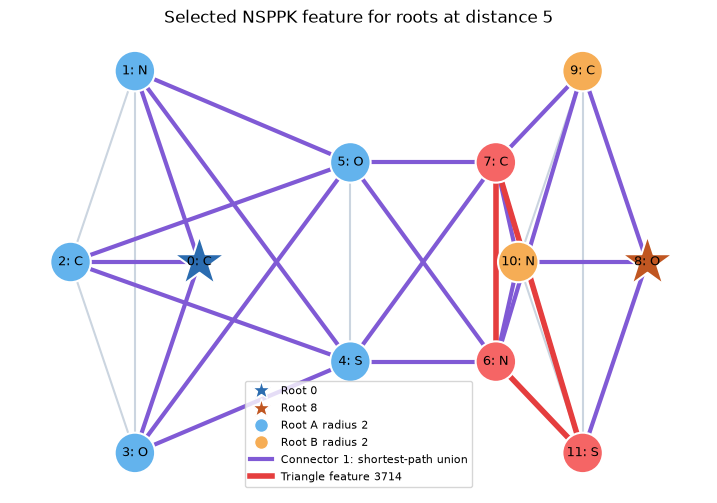

In [3]:
from matplotlib.lines import Line2D
from nsppk import get_feature_archive

root_a, root_b = 0, 8
root_distance = nx.shortest_path_length(dense_graph, root_a, root_b)
assert root_distance == 5, f'Expected roots at distance 5, got {root_distance}'

radius = 2
distance = 5
connector = 1
ball_a = set(nx.single_source_shortest_path_length(dense_graph, root_a, cutoff=radius))
ball_b = set(nx.single_source_shortest_path_length(dense_graph, root_b, cutoff=radius))
assert ball_a.isdisjoint(ball_b), 'Radius-2 root neighborhoods should be disjoint.'
shortest_paths = list(nx.all_shortest_paths(dense_graph, root_a, root_b))
connector_nodes = set().union(*(set(path) for path in shortest_paths))
connector_edges = {
    frozenset((u, v))
    for path in shortest_paths
    for u, v in zip(path, path[1:])
}

archive = get_feature_archive(
    dense_graph, graph_index=0, radius=radius, distance=distance,
    connector=connector, nbits=NBITS, use_simplex_features=True,
    simplex_feature_order=SIMPLEX_FEATURE_ORDER,
)
triangle_feature = None
for feature_id, occurrences in archive.items():
    for occurrence in occurrences:
        if (
            occurrence['feature_kind'] == 'simplex_path_union'
            and occurrence['root_node'] == root_a
            and occurrence['target_node'] == root_b
            and len(occurrence['source_node_ids']) == 3
            and len(occurrence['source_edge_ids']) == 3
        ):
            triangle_feature = (feature_id, occurrence)
            break
    if triangle_feature is not None:
        break
if triangle_feature is None:
    raise RuntimeError('No triangle feature was found for the selected distance-4 root pair.')

feature_id, occurrence = triangle_feature
triangle_nodes = set(occurrence['source_node_ids'])
triangle_edges = {frozenset(edge_id[:2]) for edge_id in occurrence['source_edge_ids']}
print(f'Roots: {root_a} and {root_b}; shortest-path distance: {root_distance}; radius-2 overlap: {bool(ball_a & ball_b)}')
print(f'Radius-2 neighborhood of root {root_a}: {sorted(ball_a)}')
print(f'Radius-2 neighborhood of root {root_b}: {sorted(ball_b)}')
print(f'Connector size 1 shortest-path union nodes: {sorted(connector_nodes)}')
print(f'Selected order-2 triangle feature hash: {feature_id}; nodes: {sorted(triangle_nodes)}')

node_colors = []
for node in dense_graph.nodes():
    if node in triangle_nodes:
        node_colors.append('#f56565')
    elif node in ball_a and node in ball_b:
        node_colors.append('#9f7aea')
    elif node in ball_a:
        node_colors.append('#63b3ed')
    elif node in ball_b:
        node_colors.append('#f6ad55')
    else:
        node_colors.append('#e2e8f0')
path_edges = [(u, v) for u, v in dense_graph.edges() if frozenset((u, v)) in connector_edges]
triangle_edge_list = [(u, v) for u, v in dense_graph.edges() if frozenset((u, v)) in triangle_edges]
background_edges = [(u, v) for u, v in dense_graph.edges() if (u, v) not in path_edges and (v, u) not in path_edges]

fig, ax = plt.subplots(figsize=(9, 6))
nx.draw_networkx_edges(dense_graph, pos, edgelist=background_edges, edge_color='#cbd5e0', width=1.5, ax=ax)
nx.draw_networkx_edges(dense_graph, pos, edgelist=path_edges, edge_color='#805ad5', width=3, ax=ax)
nx.draw_networkx_edges(dense_graph, pos, edgelist=triangle_edge_list, edge_color='#e53e3e', width=4, ax=ax)
ordinary_nodes = [node for node in dense_graph if node not in (root_a, root_b)]
nx.draw_networkx_nodes(dense_graph, pos, nodelist=ordinary_nodes, node_color=[node_colors[node] for node in ordinary_nodes], node_size=850, edgecolors='white', linewidths=1.5, ax=ax)
nx.draw_networkx_nodes(dense_graph, pos, nodelist=[root_a], node_color='#2b6cb0', node_shape='*', node_size=1500, edgecolors='white', linewidths=1.5, ax=ax)
nx.draw_networkx_nodes(dense_graph, pos, nodelist=[root_b], node_color='#c05621', node_shape='*', node_size=1500, edgecolors='white', linewidths=1.5, ax=ax)
nx.draw_networkx_labels(dense_graph, pos, labels={node: f'{node}: {node_labels[node]}' for node in dense_graph}, font_size=9, ax=ax)
legend_items = [
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#2b6cb0', markersize=14, label=f'Root {root_a}'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#c05621', markersize=14, label=f'Root {root_b}'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#63b3ed', markersize=10, label='Root A radius 2'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#f6ad55', markersize=10, label='Root B radius 2'),
    Line2D([0], [0], color='#805ad5', linewidth=3, label='Connector 1: shortest-path union'),
    Line2D([0], [0], color='#e53e3e', linewidth=4, label=f'Triangle feature {feature_id}'),
]
ax.legend(handles=legend_items, loc='best', frameon=True, fontsize=8)
ax.set_title('Selected NSPPK feature for roots at distance 5')
ax.axis('off');

### Other order-2 fragments in the example graph

Each triangle is an order-2 simplex: three distinct vertices with all three edges present. The highlighted triangle above is one of these fragments, selected from the distance-4 connector feature archive.

order-2 simplex fragments in the example graph: 30


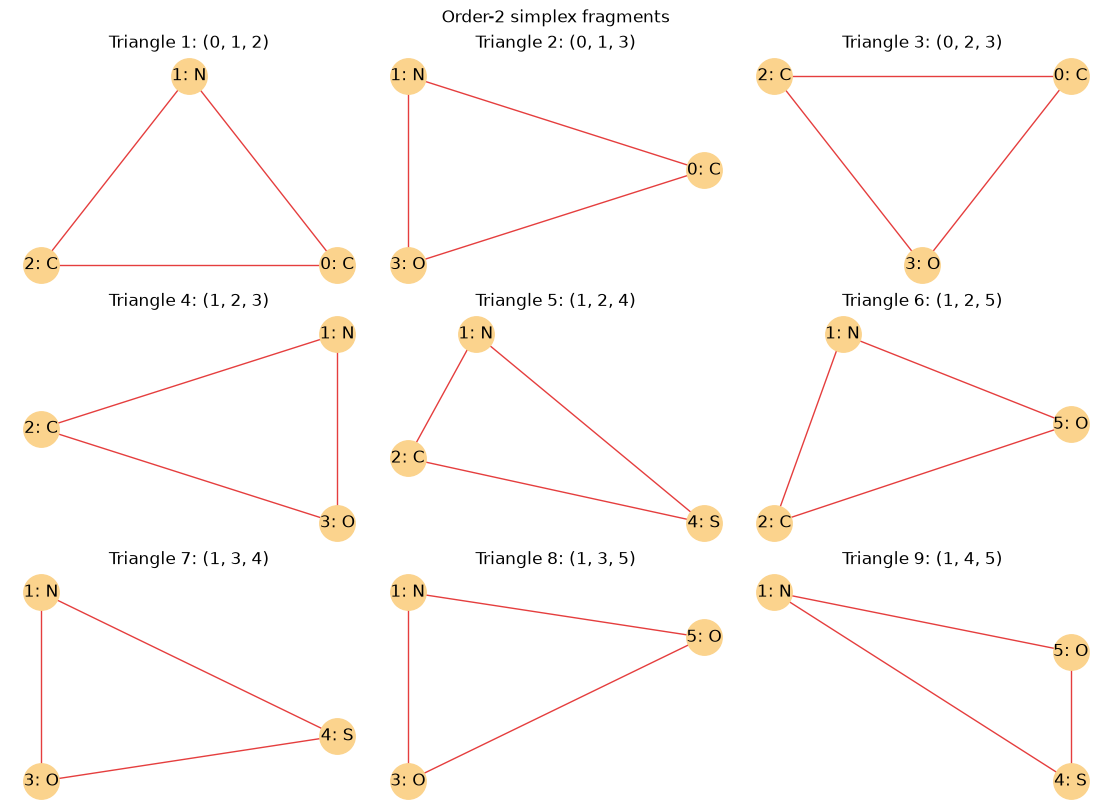

In [4]:
triangle_fragments = [
    tuple(clique)
    for clique in nx.enumerate_all_cliques(dense_graph)
    if len(clique) == 3
]
print(f'order-2 simplex fragments in the example graph: {len(triangle_fragments)}')
shown_triangles = triangle_fragments[:min(9, len(triangle_fragments))]
fig, axes = plt.subplots(3, 3, figsize=(11, 8), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    if index >= len(shown_triangles):
        ax.axis('off')
        continue
    triangle = shown_triangles[index]
    fragment = dense_graph.subgraph(triangle)
    nx.draw_networkx(
        fragment, pos=pos, ax=ax, with_labels=True,
        labels={node: f'{node}: {node_labels[node]}' for node in triangle},
        node_color='#fbd38d', edge_color='#e53e3e', node_size=650,
    )
    ax.set_title(f'Triangle {index + 1}: {triangle}')
    ax.axis('off')
fig.suptitle('Order-2 simplex fragments');

In [5]:
sweep_configs = {
    'Radius': [(radius, 0, 0, radius) for radius in range(3)],
    'Distance': [(1, distance, 0, distance) for distance in range(5)],
    'Connector': [(1, 4, connector, connector) for connector in range(3)],
}

dense_rows = []
dense_vectors = {}
for sweep_name, configs in sweep_configs.items():
    for radius, distance, connector, sweep_value in configs:
        for use_simplex in (False, True):
            model = NSPPK(
                radius=radius, distance=distance, connector=connector,
                nbits=NBITS, dense=False, parallel=False,
                use_simplex_features=use_simplex,
                simplex_feature_order=SIMPLEX_FEATURE_ORDER,
            )
            started = time.perf_counter()
            vector = model.fit_transform([dense_graph]).toarray()[0]
            elapsed = time.perf_counter() - started
            dense_vectors[(sweep_name, sweep_value, use_simplex)] = vector
            dense_rows.append({
                'sweep': sweep_name,
                'setting': sweep_value,
                'radius': radius,
                'distance': distance,
                'connector': connector,
                'simplex_features': use_simplex,
                'active_feature_bins': int(np.count_nonzero(vector)),
                'structural_bins': int(np.count_nonzero(vector[2:])),
                'feature_mass': float(vector.sum()),
                'runtime_sec': elapsed,
            })

dense_results_df = pd.DataFrame(dense_rows)
display(dense_results_df.round(4))


,sweep,setting,radius,distance,connector,simplex_features,active_feature_bins,structural_bins,feature_mass,runtime_sec
0,Radius,0,0,0,0,False,6,4,84.0,0.0019
1,Radius,0,0,0,0,True,10,8,96.0,0.0017
2,Radius,1,1,0,0,False,41,39,120.0,0.0006
3,Radius,1,1,0,0,True,1641,1639,12580.0,0.0198
4,Radius,2,2,0,0,False,100,98,180.0,0.0007
5,Radius,2,2,0,0,True,1892,1890,80870.0,0.1071
6,Distance,0,1,0,0,False,41,39,120.0,0.0005
7,Distance,0,1,0,0,True,1641,1639,12580.0,0.0180
8,Distance,1,1,1,0,False,188,186,360.0,0.0007
9,Distance,1,1,1,0,True,2045,2043,77560.0,0.0960


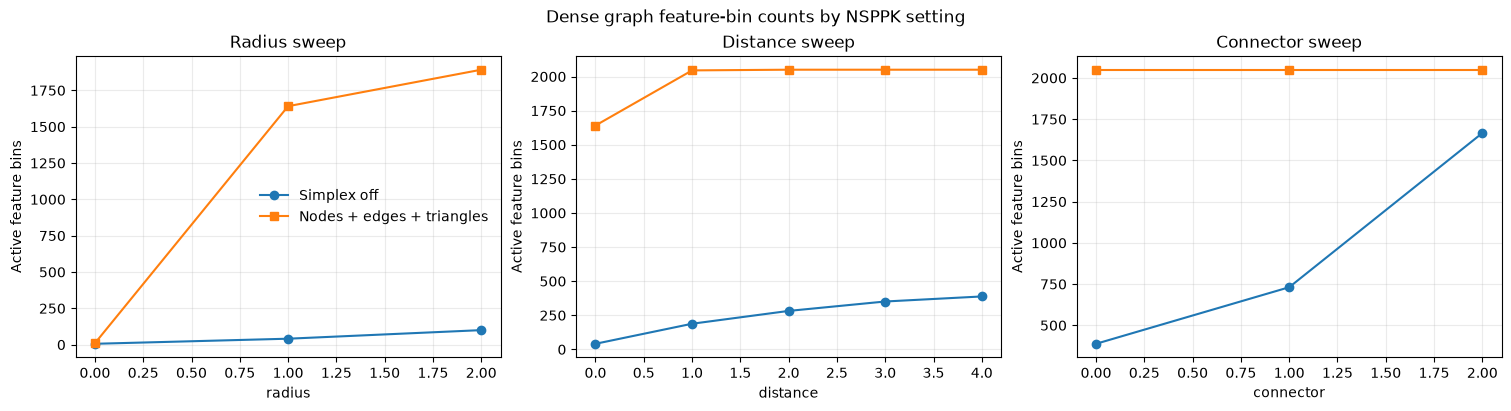

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (sweep_name, configs) in zip(axes, sweep_configs.items()):
    plot_df = dense_results_df[dense_results_df['sweep'] == sweep_name]
    for use_simplex, label, marker in ((False, 'Simplex off', 'o'), (True, 'Nodes + edges + triangles', 's')):
        series = plot_df[plot_df['simplex_features'] == use_simplex].sort_values('setting')
        ax.plot(series['setting'], series['active_feature_bins'], marker=marker, label=label)
    ax.set_title(f'{sweep_name} sweep')
    ax.set_xlabel(sweep_name.lower())
    ax.set_ylabel('Active feature bins')
    ax.grid(alpha=0.25)
axes[0].legend(frameon=False)
fig.suptitle('Dense graph feature-bin counts by NSPPK setting');


## 2. HIV graph sample and fixed split

The repository includes NetworkX graphs and activity labels in `data/HIV_networkx_graphs.pkl`, so this section does not download data or rebuild molecules. The positive class is rare in the full dataset; for a quick, interpretable comparison, the code selects the same number of active and inactive molecules and uses a stratified 75/25 split. The sample size can be increased below.

In [7]:
SAMPLE_PER_CLASS = 100  # 200 molecules total by default
with HIV_PICKLE.open('rb') as handle:
    hiv_data = pickle.load(handle)
hiv_graphs_all = hiv_data['graphs']
hiv_labels_all = np.asarray(hiv_data['labels'], dtype=int)

rng = np.random.default_rng(RANDOM_STATE)
class_indices = [np.flatnonzero(hiv_labels_all == label) for label in (0, 1)]
if any(len(indices) < SAMPLE_PER_CLASS for indices in class_indices):
    raise ValueError('SAMPLE_PER_CLASS exceeds the available HIV examples in a class.')
sampled_indices = np.concatenate([
    rng.choice(indices, size=SAMPLE_PER_CLASS, replace=False)
    for indices in class_indices
])
rng.shuffle(sampled_indices)
hiv_graphs = [hiv_graphs_all[index] for index in sampled_indices]
hiv_labels = hiv_labels_all[sampled_indices]
train_indices, test_indices = train_test_split(
    np.arange(len(hiv_graphs)), test_size=0.25,
    random_state=RANDOM_STATE, stratify=hiv_labels,
)
print(f'Full bundled dataset: {len(hiv_graphs_all):,} graphs; class counts={np.bincount(hiv_labels_all).tolist()}')
print(f'Benchmark sample: {len(hiv_graphs):,} balanced graphs; train={len(train_indices)}, test={len(test_indices)}')
print(f'Train class counts={np.bincount(hiv_labels[train_indices]).tolist()}, test class counts={np.bincount(hiv_labels[test_indices]).tolist()}')


Full bundled dataset: 41,120 graphs; class counts=[39677, 1443]
Benchmark sample: 200 balanced graphs; train=150, test=50
Train class counts=[75, 75], test class counts=[25, 25]


## 3. HIV runtime and classification accuracy

Every unique `(radius, distance, connector)` combination from the three sweeps is evaluated with simplex features off and on. Duplicate parameter combinations across sweeps are computed once and labeled with both sweep names. NSPPK feature generation is timed separately from logistic-regression fitting and prediction. Accuracy and balanced accuracy are measured on the same held-out test molecules for every run.

In [8]:
config_groups = {}
for sweep_name, configs in sweep_configs.items():
    for radius, distance, connector, sweep_value in configs:
        key = (radius, distance, connector)
        config_groups.setdefault(key, []).append((sweep_name, sweep_value))

hiv_rows = []
for (radius, distance, connector), group_values in config_groups.items():
    sweep_labels = ', '.join(f'{name}={value}' for name, value in group_values)
    for use_simplex in (False, True):
        vectorizer = NSPPK(
            radius=radius, distance=distance, connector=connector,
            nbits=NBITS, dense=False, parallel=False,
            use_simplex_features=use_simplex,
            simplex_feature_order=SIMPLEX_FEATURE_ORDER,
        )
        feature_started = time.perf_counter()
        feature_matrix = vectorizer.fit_transform(hiv_graphs)
        feature_seconds = time.perf_counter() - feature_started

        classifier = LogisticRegression(
            solver='liblinear', max_iter=300, class_weight='balanced',
            random_state=RANDOM_STATE,
        )
        fit_started = time.perf_counter()
        classifier.fit(feature_matrix[train_indices], hiv_labels[train_indices])
        classifier_fit_seconds = time.perf_counter() - fit_started

        predict_started = time.perf_counter()
        predictions = classifier.predict(feature_matrix[test_indices])
        predict_seconds = time.perf_counter() - predict_started
        accuracy = accuracy_score(hiv_labels[test_indices], predictions)
        balanced_accuracy = balanced_accuracy_score(hiv_labels[test_indices], predictions)

        hiv_rows.append({
            'sweeps': sweep_labels,
            'radius': radius,
            'distance': distance,
            'connector': connector,
            'simplex_features': use_simplex,
            'simplex_feature_order': SIMPLEX_FEATURE_ORDER if use_simplex else None,
            'feature_runtime_sec': feature_seconds,
            'classifier_fit_sec': classifier_fit_seconds,
            'predict_sec': predict_seconds,
            'end_to_end_sec': feature_seconds + classifier_fit_seconds + predict_seconds,
            'accuracy': accuracy,
            'balanced_accuracy': balanced_accuracy,
            'feature_nnz': int(feature_matrix.nnz),
        })
        print(
            f'{sweep_labels:30s} simplex={use_simplex!s:5s} '
            f'features={feature_seconds:7.2f}s accuracy={accuracy:.3f} '
            f'balanced_accuracy={balanced_accuracy:.3f}'
        )

hiv_results_df = pd.DataFrame(hiv_rows)
display(hiv_results_df.round(4))


Radius=0                       simplex=False features=   0.14s accuracy=0.520 balanced_accuracy=0.520
Radius=0                       simplex=True  features=   0.28s accuracy=0.520 balanced_accuracy=0.520
Radius=1, Distance=0           simplex=False features=   0.17s accuracy=0.600 balanced_accuracy=0.600
Radius=1, Distance=0           simplex=True  features=   0.94s accuracy=0.660 balanced_accuracy=0.660
Radius=2                       simplex=False features=   0.19s accuracy=0.560 balanced_accuracy=0.560
Radius=2                       simplex=True  features=   3.71s accuracy=0.620 balanced_accuracy=0.620
Distance=1                     simplex=False features=   0.20s accuracy=0.540 balanced_accuracy=0.540
Distance=1                     simplex=True  features=   1.68s accuracy=0.620 balanced_accuracy=0.620
Distance=2                     simplex=False features=   0.30s accuracy=0.580 balanced_accuracy=0.580
Distance=2                     simplex=True  features=   2.83s accuracy=0.620 bala

,sweeps,radius,distance,connector,simplex_features,simplex_feature_order,feature_runtime_sec,classifier_fit_sec,predict_sec,end_to_end_sec,accuracy,balanced_accuracy,feature_nnz
0,Radius=0,0,0,0,False,NaN,0.1379,0.0034,0.0004,0.1416,0.52,0.52,2210
1,Radius=0,0,0,0,True,2.0,0.2756,0.0021,0.0001,0.2778,0.52,0.52,4017
2,"Radius=1, Distance=0",1,0,0,False,NaN,0.1721,0.0021,0.0001,0.1742,0.60,0.60,14678
3,"Radius=1, Distance=0",1,0,0,True,2.0,0.9355,0.0095,0.0002,0.9452,0.66,0.66,48068
4,Radius=2,2,0,0,False,NaN,0.1946,0.0028,0.0001,0.1975,0.56,0.56,35598
5,Radius=2,2,0,0,True,2.0,3.7064,0.0171,0.0002,3.7237,0.62,0.62,124848
6,Distance=1,1,1,0,False,NaN,0.2046,0.0040,0.0001,0.2087,0.54,0.54,42170
7,Distance=1,1,1,0,True,2.0,1.6819,0.0171,0.0002,1.6992,0.62,0.62,120451
8,Distance=2,1,2,0,False,NaN,0.3036,0.0064,0.0001,0.3102,0.58,0.58,76107
9,Distance=2,1,2,0,True,2.0,2.8262,0.0246,0.0002,2.8510,0.62,0.62,193292


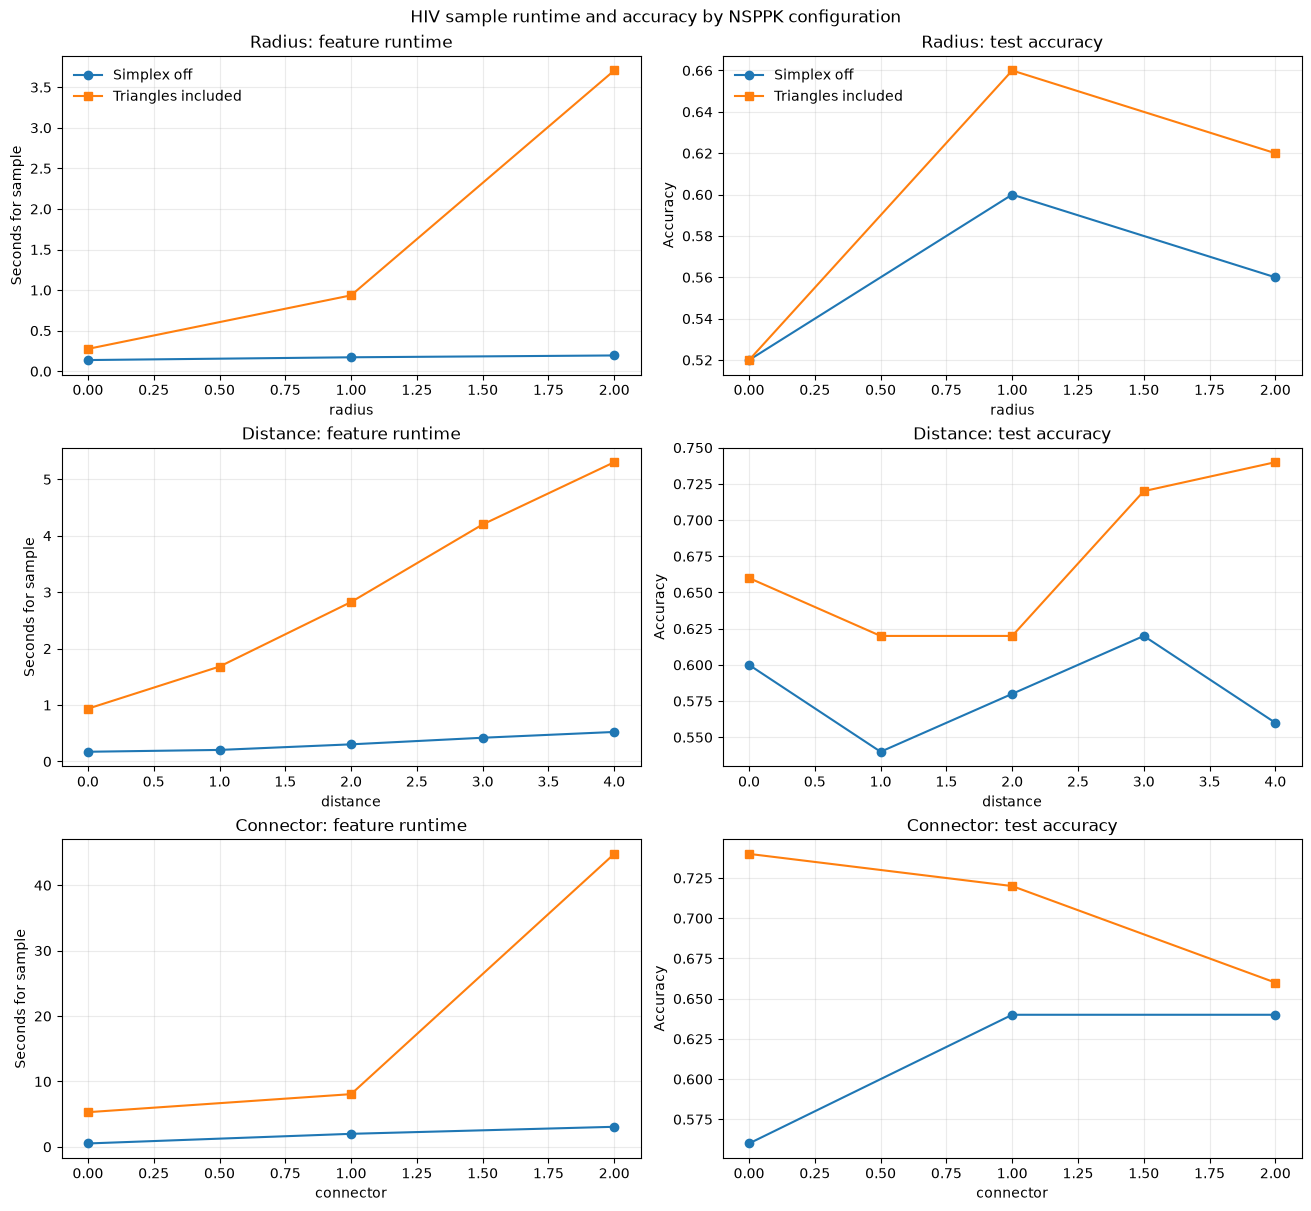

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12), constrained_layout=True)
for row, sweep_name in enumerate(('Radius', 'Distance', 'Connector')):
    sweep_df = hiv_results_df[hiv_results_df['sweeps'].str.contains(rf'{sweep_name}=')].copy()
    value_column = sweep_name.lower()
    for use_simplex, label, marker in ((False, 'Simplex off', 'o'), (True, 'Triangles included', 's')):
        series = sweep_df[sweep_df['simplex_features'] == use_simplex].sort_values(value_column)
        axes[row, 0].plot(series[value_column], series['feature_runtime_sec'], marker=marker, label=label)
        axes[row, 1].plot(series[value_column], series['accuracy'], marker=marker, label=label)
    axes[row, 0].set_title(f'{sweep_name}: feature runtime')
    axes[row, 0].set_ylabel('Seconds for sample')
    axes[row, 1].set_title(f'{sweep_name}: test accuracy')
    axes[row, 1].set_ylabel('Accuracy')
    for ax in axes[row]:
        ax.set_xlabel(sweep_name.lower())
        ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
axes[0, 1].legend(frameon=False)
fig.suptitle('HIV sample runtime and accuracy by NSPPK configuration');


## Interpretation

- `active_feature_bins` and `feature_nnz` count occupied hashed columns. They are not exact counts of unique simplex fragments because different signatures can collide into the same bin.
- Simplex order 2 adds triangle fragments; high-degree neighborhoods can therefore cost more than baseline hashing. The per-graph cache reuses fragments for repeated induced neighborhoods and path regions within each transform.
- HIV results here are a quick balanced-sample comparison from one split. Increase `SAMPLE_PER_CLASS` and repeat stratified splits before using the accuracy values as model-selection evidence. Compare balanced accuracy alongside accuracy because the full HIV labels are strongly imbalanced.